<a href="https://colab.research.google.com/github/Deshawa77/pusl3123-a1/blob/main/Exercise3_Regularisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount("/content/drive")
import os, sys, random, json, time, copy
PROJECT = "/content/drive/MyDrive/pusl3123-a1"
assert os.path.isdir(PROJECT), "Folder not found"
os.chdir(PROJECT)
assert os.path.exists("split.npy"), "split.npy missing"

import numpy as np, pandas as pd
import torch, torch.nn as nn
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | torch 2.14.1+cu130


In [3]:
MEAN = (0.49181848764419556, 0.4826730489730835, 0.44718557596206665)
STD  = (0.246906116604805, 0.2434273362159729, 0.2615409195423126)

norm = [T.ToTensor(), T.Normalize(MEAN, STD)]
base_tf = T.Compose(norm)
aug_variants = {                                   # training-only transforms
    "shift_flip": T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip()] + norm),
    "rotate":     T.Compose([T.RandomRotation(10)] + norm),     # optional extra experiment
}
R = "/content/data"
full_clean = torchvision.datasets.CIFAR10(R, train=True, download=True, transform=base_tf)
aug_sets   = {k: torchvision.datasets.CIFAR10(R, train=True, download=True, transform=v)
              for k, v in aug_variants.items()}
test_set   = torchvision.datasets.CIFAR10(R, train=False, download=True, transform=base_tf)

perm = np.load("split.npy")
train_idx, val_idx = perm[:45000].tolist(), perm[45000:].tolist()
assert len(set(train_idx) & set(val_idx)) == 0

BATCH = 128
def make_train_loader(aug, seed):
    """aug = None (clean) or a key of aug_variants. Fresh generator per run, so shuffle order depends only on the seed."""
    g = torch.Generator(); g.manual_seed(seed)
    ds = Subset(aug_sets[aug] if aug else full_clean, train_idx)
    return DataLoader(ds, batch_size=BATCH, shuffle=True, generator=g,
                      num_workers=2 if aug else 0, persistent_workers=bool(aug))

train_loader_eval = DataLoader(Subset(full_clean, train_idx), batch_size=512, shuffle=False)  # clean train accuracy
val_loader  = DataLoader(Subset(full_clean, val_idx), batch_size=512, shuffle=False)          # never augmented
test_loader = DataLoader(test_set, batch_size=512, shuffle=False)                              # final scoring only
assert val_loader.dataset.dataset is full_clean        # guard: validation is the clean dataset
print(len(train_idx), len(val_idx), len(test_set))

100%|██████████| 170M/170M [14:53<00:00, 191kB/s]


45000 5000 10000


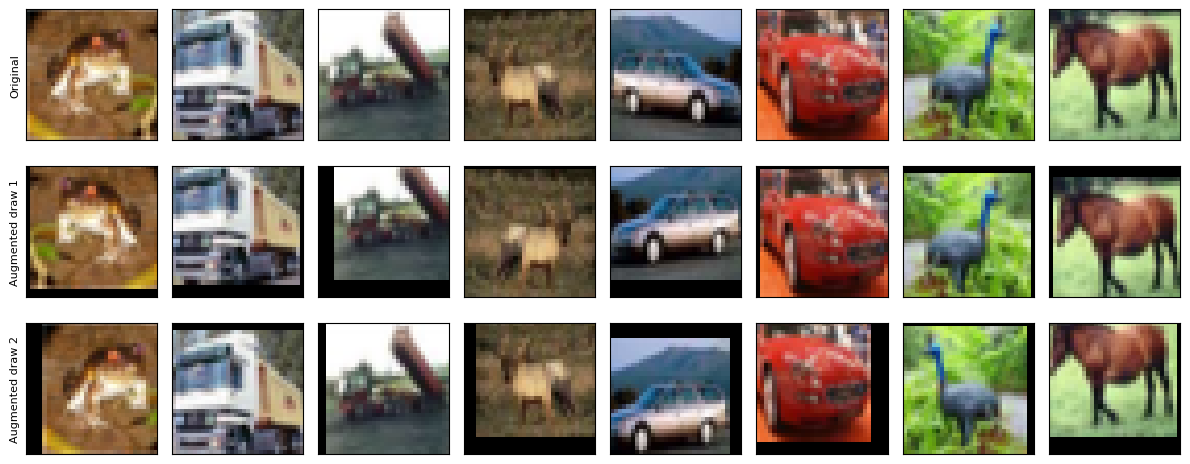

In [4]:
def denorm(t):
    m, s = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0)

fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for j in range(8):
    axes[0, j].imshow(denorm(full_clean[j][0]))
    for r in (1, 2):
        axes[r, j].imshow(denorm(aug_sets["shift_flip"][j][0]))
for r, lab in enumerate(["Original", "Augmented draw 1", "Augmented draw 2"]):
    axes[r, 0].set_ylabel(lab, fontsize=8)
for a in axes.flat: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig("figures/ex3_augmentation_examples.png", dpi=200); plt.show()

In [5]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    crit = nn.CrossEntropyLoss()
    total, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total += crit(out, yb).item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item(); n += xb.size(0)
    return total / n, correct / n

def fit_both(model, train_loader, val_loader, epochs=30, lr=1e-3, name="run", every=5):
    """Same Adam / lr / epochs / best-val-loss rule as fit(), but returns BOTH the best-validation
    weights and the final-epoch weights instead of restoring the best ones."""
    model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time"]}
    best_val, best_state, best_epoch = float("inf"), None, -1
    for ep in range(epochs):
        t0 = time.time(); model.train()
        run, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            out = model(xb); loss = crit(out, yb)
            loss.backward(); opt.step()
            run += loss.item() * xb.size(0); correct += (out.argmax(1) == yb).sum().item(); n += xb.size(0)
        vl, va = evaluate(model, val_loader)
        hist["train_loss"].append(run / n); hist["train_acc"].append(correct / n)
        hist["val_loss"].append(vl); hist["val_acc"].append(va); hist["epoch_time"].append(time.time() - t0)
        if vl < best_val:
            best_val, best_epoch = vl, ep; best_state = copy.deepcopy(model.state_dict())
        if (ep + 1) % every == 0 or ep == 0:
            print(f"[{name}] ep {ep+1:02d} | train {run/n:.3f}/{correct/n:.3f} | val {vl:.3f}/{va:.3f}")
    last_state = copy.deepcopy(model.state_dict())
    hist.update(best_epoch=best_epoch, params=count_params(model), name=name)
    return hist, best_state, last_state

In [6]:
class CNN(nn.Module):                      # Exercise 2 baseline, unchanged
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Linear(64 * 8 * 8, 10)
    def forward(self, x): return self.classifier(self.features(x).flatten(1))

class CNNDrop(nn.Module):                  # identical layers and init order; dropout before the dense layer
    def __init__(self, p=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Dropout(p), nn.Linear(64 * 8 * 8, 10))
    def forward(self, x): return self.classifier(self.features(x).flatten(1))

set_seed(42)
print("baseline:", count_params(CNN()), "| dropout:", count_params(CNNDrop()))   # both 60362

baseline: 60362 | dropout: 60362


In [7]:
CONFIGS = {
    "base": (0.0, None),
    "drop": (0.5, None),
    "aug":  (0.0, "shift_flip"),
    "both": (0.5, "shift_flip"),
    # optional extras, uncomment to run:
    # "drop02":  (0.2, None),
    # "aug_rot": (0.0, "rotate"),
}

def snapshot(model, state):
    model.load_state_dict(state)
    tr = evaluate(model, train_loader_eval)[1]
    vl, va = evaluate(model, val_loader)
    te = evaluate(model, test_loader)[1]
    return dict(train_acc=tr, val_loss=vl, val_acc=va, test_acc=te, gap=tr - te)

def run_config(config, seed, epochs=30):
    name = f"ex3_{config}_s{seed}"
    path = f"results/{name}.json"
    if os.path.exists(path):
        return json.load(open(path))
    p, aug = CONFIGS[config]
    set_seed(seed)
    model = CNNDrop(p) if p > 0 else CNN()
    hist, best_state, last_state = fit_both(model, make_train_loader(aug, seed), val_loader, epochs, name=name)
    res = dict(config=config, seed=seed, params=count_params(model), history=hist,
               best_epoch=hist["best_epoch"] + 1,
               best=snapshot(model, best_state), last=snapshot(model, last_state))
    json.dump(res, open(path, "w"))
    return res

In [8]:
SEEDS = [42]                     # later: [42, 43, 44]
results = {(c, s): run_config(c, s) for s in SEEDS for c in CONFIGS}

# sanity check: the retrained baseline should reproduce your Exercise 2 run (tiny GPU non-determinism is normal)
if os.path.exists("results/cnn.json"):
    ref = json.load(open("results/cnn.json")); b = results[("base", 42)]
    print("Ex2 best epoch", ref["best_epoch"] + 1, "| Ex3 baseline", b["best_epoch"])
    print("Ex2 min val loss %.4f | Ex3 baseline %.4f" % (min(ref["val_loss"]), min(b["history"]["val_loss"])))

[ex3_base_s42] ep 01 | train 1.402/0.503 | val 1.145/0.606
[ex3_base_s42] ep 05 | train 0.756/0.740 | val 0.875/0.710
[ex3_base_s42] ep 10 | train 0.543/0.814 | val 0.897/0.715
[ex3_base_s42] ep 15 | train 0.411/0.857 | val 0.987/0.711
[ex3_base_s42] ep 20 | train 0.314/0.889 | val 1.122/0.708
[ex3_base_s42] ep 25 | train 0.239/0.917 | val 1.352/0.695
[ex3_base_s42] ep 30 | train 0.188/0.934 | val 1.515/0.699
[ex3_drop_s42] ep 01 | train 1.472/0.477 | val 1.201/0.587
[ex3_drop_s42] ep 05 | train 0.930/0.676 | val 0.881/0.707
[ex3_drop_s42] ep 10 | train 0.789/0.725 | val 0.808/0.726
[ex3_drop_s42] ep 15 | train 0.722/0.749 | val 0.749/0.752
[ex3_drop_s42] ep 20 | train 0.673/0.763 | val 0.735/0.751
[ex3_drop_s42] ep 25 | train 0.639/0.776 | val 0.717/0.759
[ex3_drop_s42] ep 30 | train 0.613/0.784 | val 0.722/0.757
[ex3_aug_s42] ep 01 | train 1.618/0.417 | val 1.308/0.540
[ex3_aug_s42] ep 05 | train 1.043/0.636 | val 0.915/0.683
[ex3_aug_s42] ep 10 | train 0.915/0.682 | val 0.829/0.715


In [9]:
def fmt(v, pct=True):
    v = np.array(v) * (100 if pct else 1)
    return f"{v.mean():.2f}" + (f" ± {v.std(ddof=1):.2f}" if len(v) > 1 else "")

def table(ckpt):
    rows = []
    for c in CONFIGS:
        R_ = [results[(c, s)] for s in SEEDS]
        rows.append({"Config": c, "Params": R_[0]["params"],
                     "BestEpoch": round(np.mean([r["best_epoch"] for r in R_]), 1),
                     "Train %": fmt([r[ckpt]["train_acc"] for r in R_]),
                     "Val %":   fmt([r[ckpt]["val_acc"] for r in R_]),
                     "Test %":  fmt([r[ckpt]["test_acc"] for r in R_]),
                     "Gap (train-test) pts": fmt([r[ckpt]["gap"] for r in R_])})
    return pd.DataFrame(rows)

t_best, t_last = table("best"), table("last")
print("Best-validation-loss checkpoint (primary):\n", t_best.to_string(index=False))
print("\nFinal-epoch weights (secondary):\n", t_last.to_string(index=False))
t_best.to_csv("results/ex3_table_best.csv", index=False); t_last.to_csv("results/ex3_table_last.csv", index=False)

Best-validation-loss checkpoint (primary):
 Config  Params  BestEpoch Train % Val % Test % Gap (train-test) pts
  base   60362        8.0   82.05 72.10  71.64                10.41
  drop   60362       29.0   85.64 76.56  75.18                10.46
   aug   60362       28.0   78.65 76.66  76.19                 2.46
  both   60362       30.0   76.59 75.72  74.81                 1.78

Final-epoch weights (secondary):
 Config  Params  BestEpoch Train % Val % Test % Gap (train-test) pts
  base   60362        8.0   95.10 69.92  69.48                25.62
  drop   60362       29.0   85.18 75.70  74.78                10.40
   aug   60362       28.0   77.86 75.74  75.59                 2.27
  both   60362       30.0   76.59 75.72  74.81                 1.78


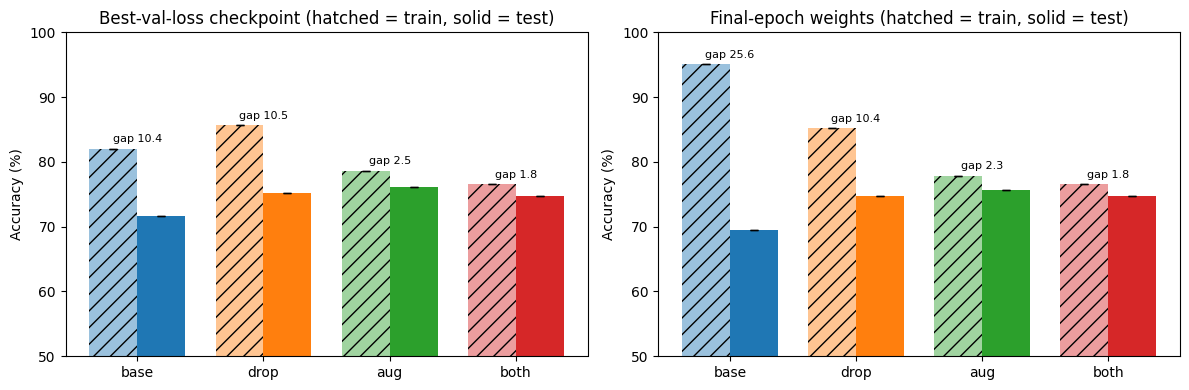

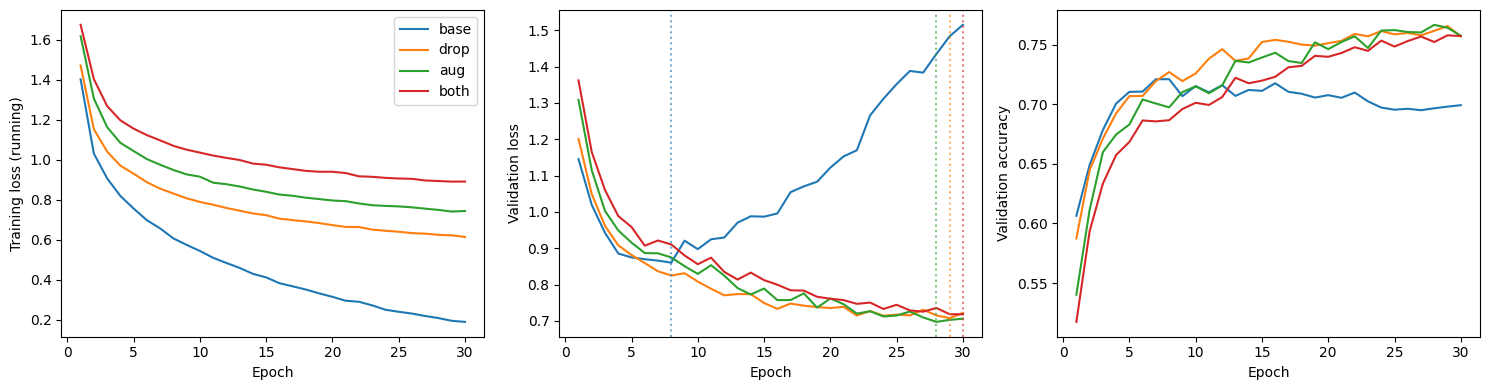

In [10]:
cols = {c: plt.cm.tab10(i) for i, c in enumerate(CONFIGS)}

def bar_panel(ax, ckpt, title):
    x, w = np.arange(len(CONFIGS)), 0.38
    for i, c in enumerate(CONFIGS):
        tr = np.array([results[(c, s)][ckpt]["train_acc"] for s in SEEDS]) * 100
        te = np.array([results[(c, s)][ckpt]["test_acc"] for s in SEEDS]) * 100
        e = lambda a: a.std(ddof=1) if len(a) > 1 else 0
        ax.bar(i - w/2, tr.mean(), w, yerr=e(tr), color=cols[c], alpha=0.45, hatch="//", capsize=3)
        ax.bar(i + w/2, te.mean(), w, yerr=e(te), color=cols[c], capsize=3)
        ax.text(i, max(tr.mean(), te.mean()) + 1, f"gap {tr.mean()-te.mean():.1f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(CONFIGS); ax.set_ylabel("Accuracy (%)"); ax.set_title(title)
    ax.set_ylim(50, 100)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bar_panel(ax[0], "best", "Best-val-loss checkpoint (hatched = train, solid = test)")
bar_panel(ax[1], "last", "Final-epoch weights (hatched = train, solid = test)")
plt.tight_layout(); plt.savefig("figures/ex3_train_vs_test.png", dpi=200); plt.show()

def mean_curve(c, key):
    return np.mean([results[(c, s)]["history"][key] for s in SEEDS], axis=0)

ep = range(1, 31)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for c in CONFIGS:
    for a, key, lab in zip(ax, ["train_loss", "val_loss", "val_acc"],
                           ["Training loss (running)", "Validation loss", "Validation accuracy"]):
        a.plot(ep, mean_curve(c, key), color=cols[c], label=c); a.set_ylabel(lab); a.set_xlabel("Epoch")
for c in CONFIGS:                                         # mark each config's best epoch
    ax[1].axvline(np.mean([results[(c, s)]["best_epoch"] for s in SEEDS]), color=cols[c], ls=":", alpha=0.6)
ax[0].legend()
plt.tight_layout(); plt.savefig("figures/ex3_curves.png", dpi=200); plt.show()

In [13]:
for ckpt in ["best", "last"]:
    m = lambda c, k: np.mean([results[(c, s)][ckpt][k] for s in SEEDS]) * 100
    print(f"\n{ckpt.upper()} checkpoint, change versus baseline (percentage points)")
    for c in [c for c in CONFIGS if c != "base"]:
        d_tr, d_te = m(c, "train_acc") - m("base", "train_acc"), m(c, "test_acc") - m("base", "test_acc")
        d_gap = m(c, "gap") - m("base", "gap")
        why = "train fell more than test" if d_tr < d_te and d_te <= 0 else \
              "test rose" if d_te > 0 else "check the numbers"
        print(f"  {c:>6}: d_train {d_tr:+.2f} | d_test {d_te:+.2f} | d_gap {d_gap:+.2f}   ({why})")


BEST checkpoint, change versus baseline (percentage points)
    drop: d_train +3.59 | d_test +3.54 | d_gap +0.05   (test rose)
     aug: d_train -3.40 | d_test +4.55 | d_gap -7.95   (test rose)
    both: d_train -5.46 | d_test +3.17 | d_gap -8.63   (test rose)

LAST checkpoint, change versus baseline (percentage points)
    drop: d_train -9.92 | d_test +5.30 | d_gap -15.22   (test rose)
     aug: d_train -17.25 | d_test +6.11 | d_gap -23.36   (test rose)
    both: d_train -18.51 | d_test +5.33 | d_gap -23.84   (test rose)
